# Building an optimal portfolio system

1) Forecast (the big one)
2) Risk model (start with sample covariance matrix)
3) Cost model (start with only spread)

### Issues:
- Universe selected from 2023-2025, but not splitting or rolling forecasts or covariance right now: **lookahead in forecasts and covariance**

## Gathering Data

In [1]:
from data_collection.data_adapters import DatabentoGenericAdapter
from dotenv import load_dotenv
from pathlib import Path
import os
import polars as pl
import numpy as np
import matplotlib.pyplot as plt
load_dotenv()
pl.enable_string_cache()

CACHE_DIR = Path.cwd().resolve().parents[0] / "data" / "dbn_cache" / "generic"
adapter = DatabentoGenericAdapter(os.getenv("DATABENTO-API-KEY"), CACHE_DIR)

print(f"CACHE_DIR: {CACHE_DIR}")
# Clear the cache if needed
# adapter.clear_cache()

with open("../universe.txt", "r") as f:
    UNIVERSE = [line.strip() for line in f]
START = "2025-06-11"
END = "2026-06-11"
DATASET = "XNAS.ITCH"

# Imbalance
df_imbalance = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="imbalance"
    )
    .select(["ts_event", "symbol", "side", "total_imbalance_qty"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# trades with the bbo
df_trades = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="tbbo"
    )
    .select(["ts_event", "symbol", "price", "size", "ask_px_00", "bid_px_00"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
)

# statistics (for the official closing auction price)
df_stats = (
    adapter.scan_data(
        tickers=UNIVERSE,
        start_date=START,
        end_date=END,
        dataset=DATASET,
        schema="statistics"
    )
    .select(["ts_event", "stat_type", "symbol", "price", "quantity"])
    .with_columns(
        pl.col('ts_event').dt.convert_time_zone("America/New_York"),
        pl.col("symbol").cast(pl.Categorical)
    )
    .filter(pl.col("stat_type") == 11)
)


CACHE_DIR: /Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/data/dbn_cache/generic
[GenericAdapter] scan_parquet: 015b0f098e17be916bbb238312a4d5d4.parquet
[GenericAdapter] scan_parquet: 6436dd54a7ced32262a3242e08d42d20.parquet
[GenericAdapter] scan_parquet: 83ab27f48711d5689292fe953cab702b.parquet


In [2]:
# daily volume before the final 10mins
session_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(15,50)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("SDV")
    )
    .sort("date")
)

avg_daily_dollar_volume = (
    df_trades
    .select((["ts_event", "symbol", "price", "size"]))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .filter(pl.col('ts_event').dt.time().is_between(pl.time(9,30), pl.time(16,00)))
    .group_by(["date", "symbol"])
    .agg(
    (pl.col('size') * pl.col("price")).sum().alias("day_volume")
    )
    .sort(["date", "symbol"])
    .with_columns(
    pl.col("day_volume").ewm_mean(span=10, adjust=True).over("symbol").alias("ADV")
    )
    .drop("day_volume")
)

auction = (
    df_stats
    .with_columns(
        pl.col("ts_event").dt.date().alias("date")
    )
    .select("date", "symbol", "price")
    .rename({"price": "auction_price"})
)

close_trades = (
    df_trades
    .with_columns(
        pl.col("ts_event").dt.date().alias("date"),
        (
            (pl.col("ask_px_00") - pl.col("bid_px_00")) / ((pl.col("ask_px_00") + pl.col("bid_px_00")) / 2) + (0.0035 / pl.col("price"))
        ).alias("spread_return")
    )
    .filter(pl.col("ts_event").dt.time().is_between(pl.time(15,45,00), pl.time(15,50,00)))          
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["price", "spread_return"]).last()
    )
    .rename({"price":"entry_price"})
)

imb_print = (
    df_imbalance
    .filter(pl.col("ts_event").dt.time() >= pl.time(15,50))
    .with_columns(pl.col("ts_event").dt.date().alias("date"))
    .group_by(["date", "symbol"], maintain_order=True)
    .agg(
        pl.col(["side", "total_imbalance_qty"]).first()
    )
)

In [3]:
data = (
    imb_print
    .join(close_trades, on=["date", "symbol"])
    .join(auction, on=["date", "symbol"])
    .join(session_dollar_volume, on=["date", "symbol"])
    .join(avg_daily_dollar_volume, on=["date", "symbol"])
    .sort(["date", "symbol"])
    .drop_nulls()
    .with_columns((pl.col("total_imbalance_qty") * pl.col("entry_price")).alias("dollar_imbalance"))
    .with_columns(
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("SDV"))
        ).alias("signed_session_imb_ratio"),
        (
            pl.when(pl.col("side") == "B").then(1)
            .when(pl.col("side") == "A").then(-1)
            .when(pl.col("side") == "N").then(0)
            *(pl.col("dollar_imbalance") / pl.col("ADV"))
        ).alias("signed_mean_imb_ratio")
    )
    .drop(["total_imbalance_qty"])
).collect(engine="streaming")

# The dataframe we will be working with
data

date,symbol,side,entry_price,spread_return,auction_price,SDV,ADV,dollar_imbalance,signed_session_imb_ratio,signed_mean_imb_ratio
date,cat,str,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-11,"""AAL""","""A""",11.035,0.001223,11.06,8.4569e7,9.7183e7,1.4006e6,-0.016562,-0.014412
2025-06-11,"""AAOI""","""B""",16.37,0.001435,16.32,1.3359e7,1.4384e7,208340.99,0.015596,0.014484
2025-06-11,"""AAON""","""B""",75.78,0.001102,75.85,3.9719e7,4.9410e7,565849.26,0.014246,0.011452
2025-06-11,"""AAPL""","""A""",198.81,0.000219,198.78,1.9584e9,2.2199e9,5.4598e7,-0.027879,-0.024595
2025-06-11,"""AAXJ""","""N""",81.8,0.000165,81.88,2.3794e7,2.4416e7,0.0,0.0,0.0
…,…,…,…,…,…,…,…,…,…,…
2026-06-10,"""ZG""","""N""",34.46,0.000392,34.1,1.2288e7,1.4582e7,0.0,0.0,0.0
2026-06-10,"""ZION""","""N""",65.56,0.000358,65.82,2.6329e7,2.7290e7,0.0,0.0,0.0
2026-06-10,"""ZLAB""","""A""",17.3,0.000781,17.26,3.5581e6,4.5611e6,1192938.8,-0.335274,-0.261546


## Forecast
OLS regression through the origin of qty_signal on returns from 3:50:00 to close. Had an R^2 of 0.0512 (from rules_based_backtest.ipynb)

In [4]:
import statsmodels.api as sm
study_data = data.with_columns((pl.col("auction_price") / pl.col("entry_price") - 1).alias("return_to_close"))
# X = sm.add_constant(study_data['signed_mean_imb_ratio'].to_numpy()) # debating whether to add .clip(-1,1)
X = study_data['signed_mean_imb_ratio'].to_numpy() # debating whether to add .clip(-1,1)

y = (study_data['return_to_close']).to_numpy()

res = sm.OLS(y, X).fit()

# print(res.summary())
print(f'beta   = {res.params[0]:+.5f}')
# print(f'beta_1  = {res.params[1]:+.5f}')
print(f'R^2     = {res.rsquared:.4f}')
print(f't(beta) = {res.tvalues[0]:+.2f}')

beta   = +0.00270
R^2     = 0.0208
t(beta) = +67.56


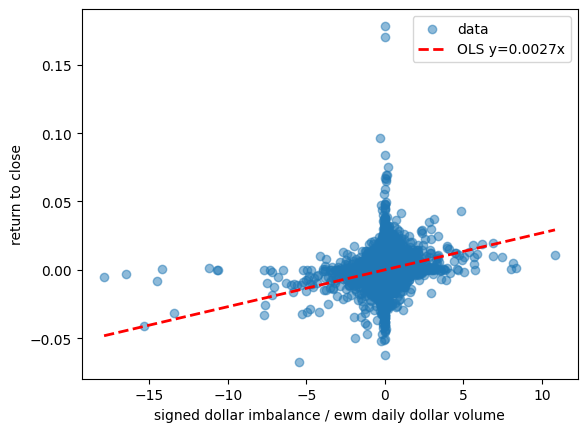

In [5]:
xs = np.linspace(np.min(X), np.max(X))
plt.scatter(X, y, alpha=0.5, label="data")
plt.plot(xs, res.params[0] * xs, label=f'OLS y={res.params[0]:,.4f}x', color='red', linestyle='--', linewidth=2)
plt.xlabel("signed dollar imbalance / ewm daily dollar volume")
plt.ylabel("return to close")
plt.legend()
plt.show()

In [6]:
from scipy.stats import spearmanr

ic, pval = spearmanr(X, y)
print(f"Spearman IC for ewm daily dollar volume: {ic:,.3f} with p-value: {pval:,.3f}")

Spearman IC for ewm daily dollar volume: 0.209 with p-value: 0.000


## Risk (Covariance) Model
Starting with a **SIMPLE** sample covariance of daily returns, filling null daily returns with the symbols **MEAN**.

Very much not a good enough covariance matrix yet. Need shrinkage or a factor model.

In [7]:
# daily_ret = (
#     df_trades
#     .select(["ts_event", "symbol", "price"])
#     .with_columns(pl.col("ts_event").dt.date().alias("date"))
#     .group_by(["date", "symbol"])
#     .agg(
#         pl.col("price").last()
#     )
#     .sort("date")
#     .with_columns(
#         pl.col("price").pct_change().over("symbol").alias("ret")
#     )
#     .pivot(
#         on="symbol",
#         on_columns=UNIVERSE,
#         index="date",
#         values="ret"
#     )
#     .with_columns(pl.all().exclude("date").fill_null(strategy="mean"))
#     .with_columns(pl.all().exclude("date").fill_null(0.0))   # dead names (no trades all window) stay all-null after mean; zero them
# )

# daily_ret = daily_ret.collect(engine="streaming")
# daily_ret

date,NVDA,SPY,TSLA,QQQ,AAPL,MSFT,AMZN,META,GOOGL,AVGO,AMD,TLT,GOOG,IWM,NFLX,TQQQ,MU,COST,ADBE,QCOM,COIN,SMCI,INTC,SMH,MSTR,TXN,AMAT,PEP,CSCO,BKNG,ASML,LRCX,TMUS,HYG,INTU,PDD,…,MMS,IGF,BITI,TNL,BANC,ASGN,OXM,ENOV,VSH,RLI,IDEV,BASE,LQDA,SCHR,VOE,ESNT,CHCO,PPH,LCII,AX,FNB,ESGD,SKYY,RITM,SHYG,TREE,AG,QQQE,ATGE,BKH,SPHY,FTSM,EFSC,TGNA,FIZZ,MAC,ANGL
date,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64
2025-06-11,0.001597,0.00078,0.001014,0.001115,0.001632,-0.000566,0.000619,-0.000532,0.002961,0.001955,0.006129,-0.000041,0.00289,0.001186,-0.004944,0.0011,0.009116,0.000015,-0.002046,0.001171,-0.000963,-0.000054,0.007623,0.003335,-0.003843,0.001691,0.004694,0.000513,0.002655,-0.005059,0.003522,0.005588,-0.000757,0.000002,-0.003545,-0.000716,…,-0.000343,0.000458,0.001798,0.001679,0.001498,-0.003261,0.000286,-0.001059,0.005564,-0.001102,0.000605,0.00382,0.006976,-0.000029,0.00074,0.000121,0.000421,0.000668,0.000255,0.001011,0.00114,0.000501,0.00068,-0.00077,-0.000038,0.000912,0.003615,0.000743,-0.00059,0.000995,-0.000029,-0.000003,0.000777,0.00118,-0.000699,0.001823,0.00002
2025-06-12,0.015051,0.003808,-0.022482,0.002273,0.00176,0.012963,0.000281,-0.001311,-0.009582,0.012214,-0.022521,0.012073,-0.010345,-0.003932,-0.004139,0.006515,0.001379,0.005366,0.003344,-0.005452,-0.038567,0.003588,0.003141,0.004927,-0.019038,-0.00005,0.0136,0.01793,0.014642,-0.000801,0.00172,0.007805,-0.010257,0.00088,0.001752,0.002617,…,0.008095,0.008599,0.018756,0.005601,-0.004248,-0.009918,-0.139519,-0.032103,0.002831,0.016885,0.00782,-0.006701,0.025168,0.002631,0.004793,0.011107,-0.002274,0.014485,-0.002813,0.005122,-0.006043,0.008041,0.002088,0.005265,0.001056,-0.033991,-0.010798,0.000623,-0.001375,-0.000174,0.000852,0.000334,-0.000748,-0.01008,-0.002942,-0.013243,0.002952
2025-06-13,-0.021,-0.011181,0.019615,-0.012592,-0.013755,-0.008496,-0.005299,-0.015084,-0.005805,-0.028819,-0.019495,-0.010151,-0.006215,-0.01828,-0.002255,-0.038705,-0.005249,-0.011692,-0.053514,-0.025142,0.006513,-0.04071,-0.029383,-0.023372,0.008137,-0.023386,-0.025808,-0.010735,-0.015659,-0.029931,-0.03193,-0.023451,-0.002973,-0.00289,-0.015935,-0.027652,…,-0.017188,-0.006687,0.015889,-0.049229,-0.030928,-0.02457,-0.083333,-0.011004,-0.048934,-0.018353,-0.011345,-0.010898,-0.025934,-0.002018,-0.011803,-0.009802,-0.012834,-0.010899,-0.026217,-0.035808,-0.026109,-0.013184,-0.017345,-0.014841,-0.002228,-0.029796,0.010916,-0.01412,0.017443,-0.011306,-0.002555,0.0,-0.022174,-0.015274,-0.019891,-0.01779,-0.003463
2025-06-16,0.019126,0.009649,0.011401,0.013873,0.009722,0.008801,0.019094,0.027877,0.011849,0.013671,0.087967,-0.009386,0.011883,0.008808,0.010922,0.041363,0.036589,-0.006399,0.024621,0.014091,0.078803,0.050252,0.028784,0.025683,-0.001463,0.021793,0.034873,0.004203,0.021522,0.013045,0.018515,0.043226,0.012674,0.002268,0.018633,0.022472,…,-0.004444,-0.017503,-0.033764,0.029916,-0.010271,0.005813,0.060268,0.010813,0.038259,-0.003082,-0.012992,0.004722,0.000355,-0.001618,0.007983,0.008022,-0.012145,-0.007713,0.02715,0.002214,0.010283,-0.013809,0.016786,0.000886,0.001763,0.034805,-0.006599,0.013269,0.012058,-0.010732,0.002561,0.000334,-0.006985,0.020377,-0.002007,0.021608,0.002606
2025-06-17,-0.004389,-0.008561,-0.038983,-0.009827,-0.013762,-0.002296,-0.006245,-0.006809,-0.004695,-0.010988,0.00538,0.012107,-0.00427,-0.010629,-0.003558,-0.029955,0.004256,-0.006725,-0.047262,-0.015425,-0.02999,-0.013278,0.002894,-0.00774,-0.018441,-0.007879,-0.013989,-0.016133,-0.002443,-0.012415,-0.019649,-0.007816,-0.041315,-0.001069,-0.004349,-0.002917,…,-0.003312,-0.008822,0.03777,-0.009141,-0.012602,-0.018301,0.012897,-0.042171,-0.026366,-0.009136,-0.011626,0.02376,-0.036906,0.002836,-0.008166,-0.018794,0.002684,-0.020544,-0.022008,-0.00563,-0.008361,-0.013775,

In [8]:
L = np.load("../covariance_research/loadings.npy")
F = np.load("../covariance_research/factor_returns.npy")
D = np.load("../covariance_research/idiosyncratic.npy")
Sigma_f = np.load("../covariance_research/factor_cov_matrix.npy")
Sigma_r = np.load("../covariance_research/cov_matrix.npy")

import scipy
scipy.linalg.sqrtm(Sigma_f)

Sigma_f_half = scipy.linalg.sqrtm(Sigma_f).real     # (10,10)
d_sqrt  = np.sqrt(np.diag(D))                    # (2000,) diagonal sqrt

In [9]:
Sigma_f.shape

(10, 10)

## Daily MVO Optimizer

In [10]:
import cvxpy as cp

class ForecastModel:
    """Maps a day's features -> dense alpha vector aligned to `universe`. Missing names -> 0."""
    def __init__(self, universe, beta_1):
        self.universe = universe
        self.sym_idx_map = {s: i for i, s in enumerate(universe)}
        self.beta_1 = beta_1
    
    def get_alpha(self, day_df: pl.DataFrame) -> np.ndarray:
        """Gets the forecast mean return using beta_1. Does not include an intercept, so that 0 signal gets 0 forecast."""
        alpha = np.zeros(len(self.universe))
        for symbol, signal in zip(day_df['symbol'], day_df["signed_mean_imb_ratio"]):
            alpha[self.sym_idx_map[symbol]] = self.beta_1 * signal
        return alpha

class CostModel:
    """Half-spread (in return space) per name; names with no quote -> large cost so the optimizer avoids them."""
    def __init__(self, universe: list):
        self.universe = universe
        self.sym_idx_map = {s:i for i, s in enumerate(universe)}
    
    def get_cost(self, day_df: pl.DataFrame) -> np.ndarray:
        cost = np.zeros(len(self.universe))
        for symbol, spread in zip(day_df["symbol"], day_df["spread_return"]):
            cost[self.sym_idx_map[symbol]] = spread * 0.5
        return cost

class Optimizer:
    """Single-Period Daily MVO system."""
    def __init__(self, universe: list):
        self.universe = universe
        self.N = len(universe)
        
    def set_problem(self, Sigma, mkt_loadings, lam, scale, vol_cap):   # scale ≈ your target book ($)
        self.scale = scale
        self.z     = cp.Variable(self.N)                       # O(1) working variable
        self.alpha = cp.Parameter(self.N)
        self.cost  = cp.Parameter(self.N, nonneg=True)
        Sig        = cp.psd_wrap(cp.Constant(Sigma))
        self.objective = cp.Maximize(
            self.alpha @ self.z
            - (lam * scale / 2) * cp.quad_form(self.z, Sig)    # λ_z = λ·scale
            - (self.cost / 2) @ cp.abs(self.z)
        )
        quad_risk = cp.norm(cp.hstack([Sigma_f_half @ L @ self.z, cp.multiply(d_sqrt, self.z)]), 2)   # = √(zᵀΣz)
        self.constraints = [
            self.z @ mkt_loadings == 0,
            cp.sum(self.z) == 0,
            quad_risk <= vol_cap / scale,   # √(zᵀΣz) ≤ vol_target, vol_target from median daily expected vol on an uncapped run
        ]
        self.problem = cp.Problem(self.objective, self.constraints)

    def solve(self, alpha, cost) -> np.ndarray:
        self.alpha.value = alpha
        self.cost.value  = cost
        self.problem.solve(warm_start=True)
        if self.problem.status not in ("optimal", "optimal_inaccurate"):
            raise RuntimeError(self.problem.status)
        return self.z.value * self.scale                       # ← optimal dollars per asset

## Parallel daily solve

Each trading day is an independent QP (the book is flat at every close), so the days fan out across processes with `joblib`'s `loky` backend (works with notebook-defined classes via cloudpickle). Each worker compiles the parametrized problem **once** and warm-starts through a contiguous chunk of days — so compile cost is paid `N_JOBS` times, not once per day. Produces `weights` in the same `{date: {symbol: w}}` shape as the serial loop, so the over-time plot above works unchanged: run this cell, then re-run the plot.

In [11]:
mkt_loadings = L[0, :]

# opt = Optimizer(UNIVERSE)
# opt.set_problem(Sigma=cov_matrix, mkt_L=mkt_loadings, lam=1e-8)
f_model = ForecastModel(UNIVERSE, beta_1 = res.params[0])
c_model = CostModel(UNIVERSE)

In [ ]:
# --- Parallel daily solve (days are independent; book is flat at every close) ---
# Fans the days across processes. Each worker compiles the parametrized QP ONCE
# and warm-starts through a contiguous chunk of days. Produces `weights` in the
# same {date: {symbol: w}} shape as the serial loop, so the over-time plot works
# unchanged. Run AFTER f_model / c_model / SYMBOLS / cov_matrix are defined.
import os
from joblib import Parallel, delayed

N_JOBS = max(1, os.cpu_count() - 2)
SCALE = 1e12         # on the order of capital
LAM = 1 / SCALE     # smaller adjustments
DAILY_VOL_CAP = 20470       # because the covariance is not in true returns, its vol-standardized

def _solve_chunk(symbols, Sigma, mkt_loadings, lam, scale, vol_cap, day_records):
    """One worker: compile the QP once, then warm-start through its chunk of days."""
    opt = Optimizer(symbols)
    opt.set_problem(Sigma=Sigma, mkt_loadings=mkt_loadings, lam=lam, scale=scale, vol_cap=vol_cap)        # compile paid once per worker, not per day
    return [(date, opt.solve(alpha, cost)) for date, alpha, cost in day_records]

def _split_contiguous(items, n):
    """Contiguous chunks so adjacent days share a worker -> warm_start actually helps."""
    k, m = divmod(len(items), n)
    return [items[i * k + min(i, m):(i + 1) * k + min(i + 1, m)] for i in range(n)]

# Build per-day (alpha, cost) in the parent (cheap, vectorized) so workers receive
# only small 1-D arrays; cov_matrix is auto-memmapped by loky and shared read-only.
all_dates = data["date"].unique().sort().to_list()
day_records = [
    (d, f_model.get_alpha(day), c_model.get_cost(day))
    for d in all_dates
    for day in [data.filter(pl.col("date") == d)]
]

chunks = [c for c in _split_contiguous(day_records, N_JOBS) if c]
chunk_results = Parallel(n_jobs=N_JOBS, backend="loky")(
    delayed(_solve_chunk)(UNIVERSE, Sigma_r, mkt_loadings, LAM, SCALE, DAILY_VOL_CAP, chunk) for chunk in chunks
)

weights = {d: dict(zip(UNIVERSE, ws)) for chunk in chunk_results for d, ws in chunk}
print(f"solved {len(weights)} days across {len(chunks)} workers")

/Users/michaelcusack-nelkin/GitHub/Summer_Research_2026/.venv/lib/python3.14/site-packages/numpy/_core/fromnumeric.py:83: RuntimeWarning: invalid value encountered in reduce
  return ufunc.reduce(obj, axis, dtype, out, **passkwargs)


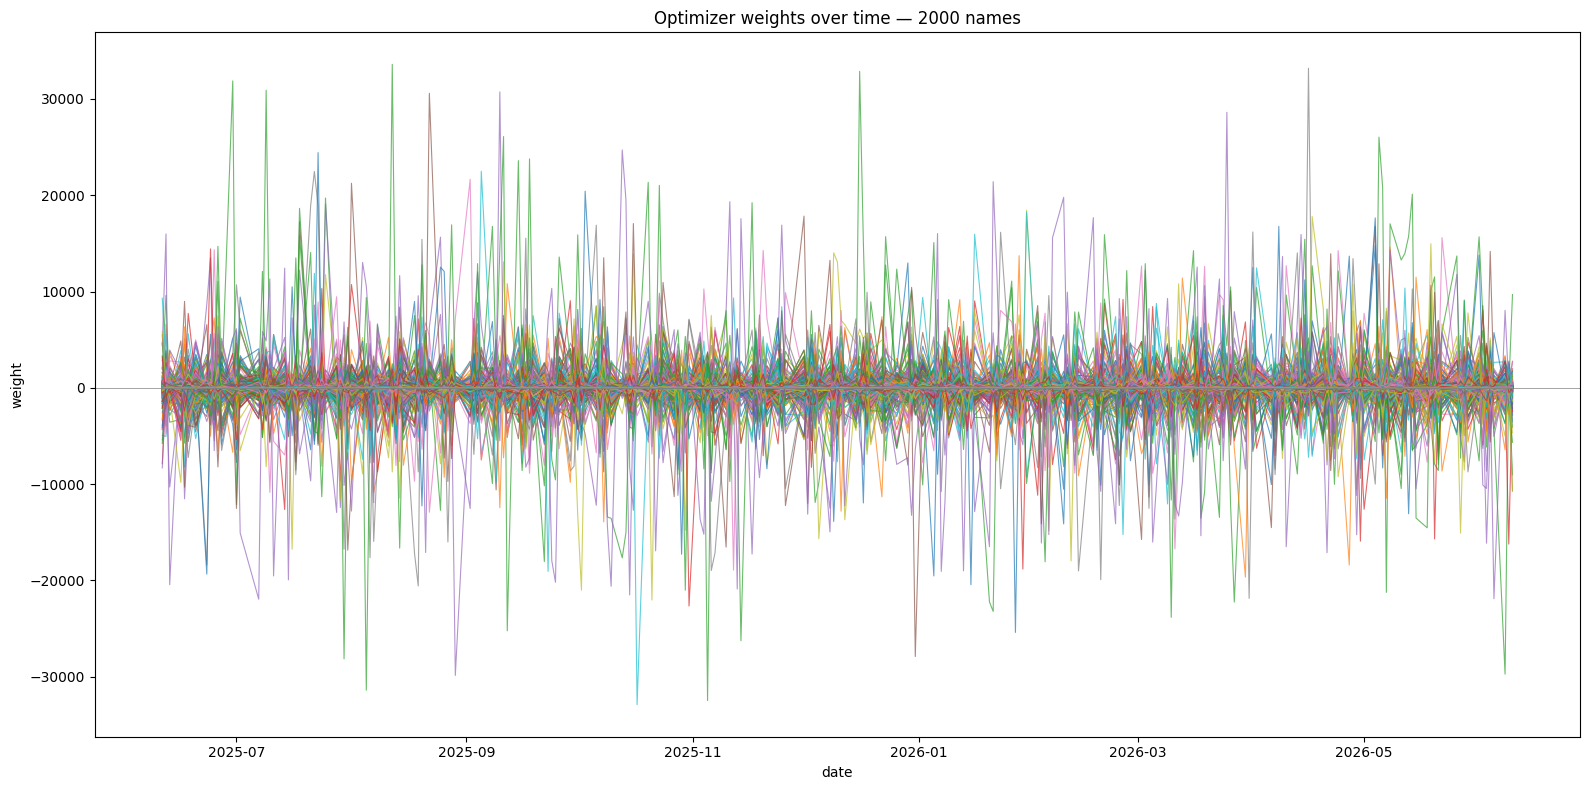

In [ ]:
# Optimizer weights over time, one line per symbol (only names ever held)
dates = sorted(weights.keys())

held = sorted({s for d in dates for s, wv in weights[d].items()})

fig, ax = plt.subplots(figsize=(16, 8))
for s in held:
    series = [weights[d].get(s, 0.0) for d in dates]
    ax.plot(dates, series, lw=0.8, alpha=0.7)

ax.axhline(0, color="grey", lw=0.5)
ax.set_xlabel("date")
ax.set_ylabel("weight")
ax.set_title(f"Optimizer weights over time — {len(held)} names")
fig.tight_layout()
plt.show()

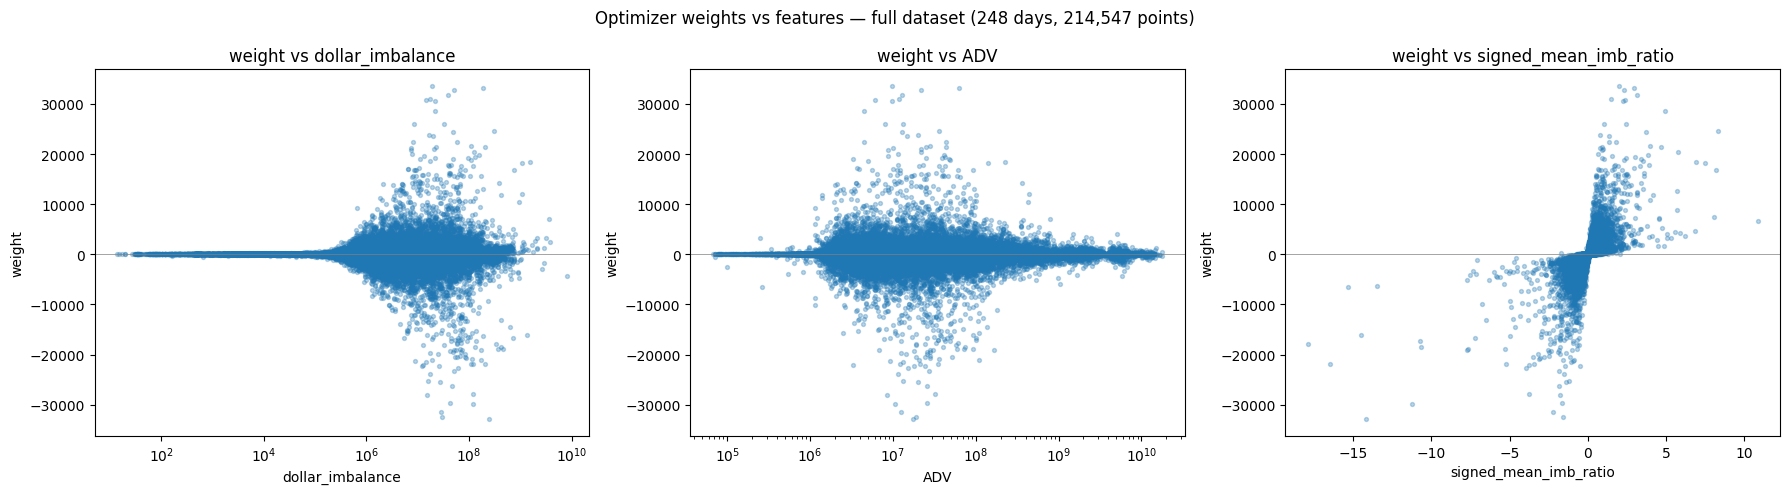

In [ ]:
# Scatter weights vs day features over the FULL dataset (all dates pooled)
# Flatten {date: {symbol: w}} -> long frame, then join each day's features from `data`.
w_long = pl.DataFrame(
    {
        "date": [d for d in weights for _ in weights[d]],
        "symbol": [s for d in weights for s in weights[d]],
        "weight": [wv for d in weights for wv in weights[d].values()],
    }
).with_columns(pl.col("symbol").cast(pl.Categorical))

plot_df = data.join(w_long, on=["date", "symbol"], how="inner")

weights_arr = plot_df["weight"].to_numpy()
features = ["dollar_imbalance", "ADV", "signed_mean_imb_ratio"]
log_x = {"dollar_imbalance", "ADV"}   # positive, span orders of magnitude; signed ratio stays linear

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, feat in zip(axes, features):
    x = plot_df[feat].to_numpy()
    ax.scatter(x, weights_arr, alpha=0.3, s=8)
    ax.axhline(0, color="grey", lw=0.5)
    if feat in log_x:
        ax.set_xscale("log")
    ax.set_xlabel(feat)
    ax.set_ylabel("weight")
    ax.set_title(f"weight vs {feat}")

fig.suptitle(f"Optimizer weights vs features — full dataset ({len(weights)} days, {len(plot_df):,} points)")
fig.tight_layout()
plt.show()

Days traded:        248
Avg gross book:     $219,792
Gross PnL:          $63,133
Total spread cost:  $17,139
Total net PnL:      $45,994
Ann. return:        +21.26%   (net daily PnL / deployed gross)
Ann. volatility:    1.77%
Sharpe (ann):       12.01
Max drawdown:       -0.11%
Daily hit rate:     85.1%


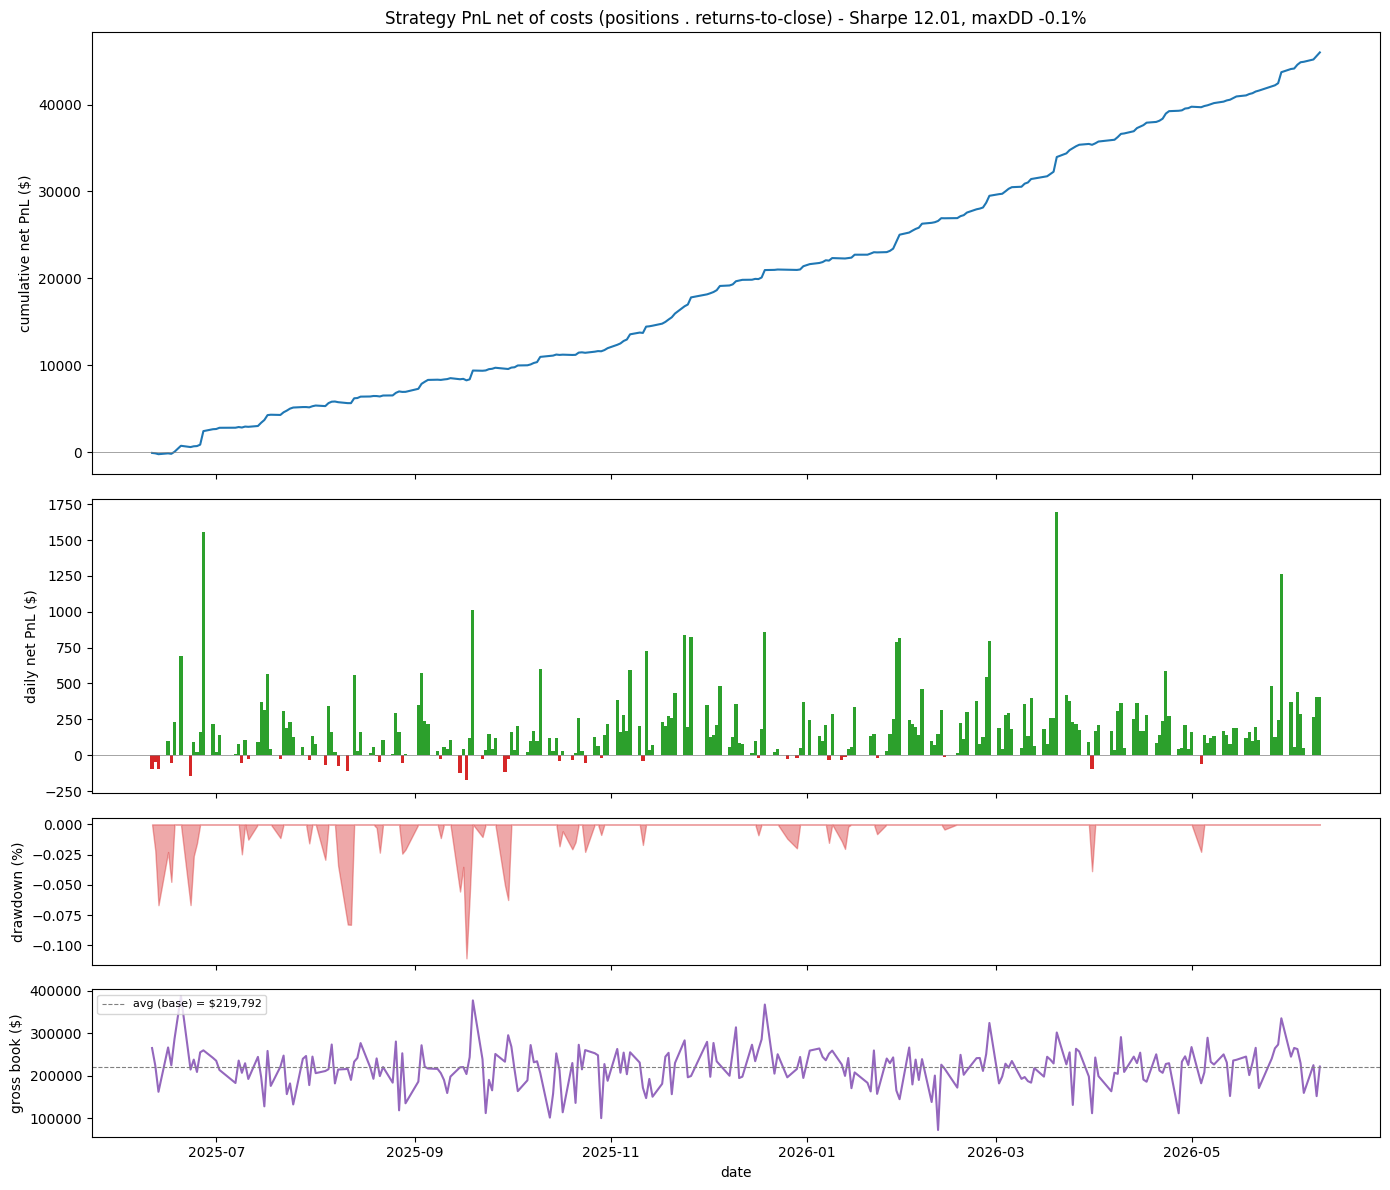

date,net_pnl,gross_pnl,spread_cost,gross,cum_pnl
date,f64,f64,f64,f64,f64
2025-06-11,-97.371503,-0.518742,96.852761,264959.806014,-97.371503
2025-06-12,-47.213011,28.905862,76.118873,224063.552207,-144.584514
2025-06-13,-99.448591,-41.169611,58.278981,162023.37201,-244.033106
2025-06-16,96.480492,194.04467,97.564177,266353.280453,-147.552613
2025-06-17,-54.123404,27.491413,81.614817,224376.636851,-201.676017
…,…,…,…,…,…
2026-06-04,284.993201,341.361591,56.36839,229055.653675,44863.49009
2026-06-05,53.288284,91.67759,38.389306,159330.91128,44916.778374
2026-06-08,265.372749,335.434818,70.062069,224693.246321,45182.151122


In [ ]:
# ===== Strategy PnL: dollar positions . returns-to-close, net of costs =====
# `weights` is the optimizer's ABSOLUTE-DOLLAR book per day: {date: {symbol: $ position}}.
# Daily gross PnL = sum_i (dollar position_i) * (return from entry to the closing auction_i).
# Costs charged:
#   - spread:     cross HALF the quoted spread on ENTRY only, on the dollar notional.
#   - commission: $0.0035 per share on BOTH legs (entry and exit).
ANN = 252
COMMISSION_PER_SHARE = 0.0035   # $/share, charged on entry AND exit (round trip)

# Flatten {date: {symbol: $pos}} -> long, then join the day's prices/spread from `data`.
pos_long = pl.DataFrame({
    "date":       [d for d in weights for _ in weights[d]],
    "symbol":     [s for d in weights for s in weights[d]],
    "dollar_pos": [w for d in weights for w in weights[d].values()],
}).with_columns(pl.col("symbol").cast(pl.Categorical))

pnl_daily = (
    data
    .join(pos_long, on=["date", "symbol"], how="inner")
    .with_columns((pl.col("auction_price") / pl.col("entry_price") - 1.0).alias("ret_to_close"))
    .with_columns(
        (pl.col("dollar_pos") * pl.col("ret_to_close")).alias("gross_pnl"),                       # $pos . return
        (pl.col("dollar_pos") // pl.col("entry_price")).alias("shares"),                          # signed share count
        (pl.col("dollar_pos").abs() * pl.col("spread_return").clip(lower_bound=0.0) / 2.0)        # half spread, ENTRY only
            .alias("spread_cost"),
    )
    .with_columns(
        (pl.col("gross_pnl") - pl.col("spread_cost")).alias("net_pnl_name"),
    )
    .group_by("date")
    .agg(
        pl.col("net_pnl_name").sum().alias("net_pnl"),
        pl.col("gross_pnl").sum().alias("gross_pnl"),
        pl.col("spread_cost").sum().alias("spread_cost"),
        pl.col("dollar_pos").abs().sum().alias("gross"),         # gross book deployed that day
    )
    .sort("date")
    .with_columns(pl.col("net_pnl").cum_sum().alias("cum_pnl"))
)

# ----- stats -----
pnl  = pnl_daily["net_pnl"].to_numpy()
cum  = pnl_daily["cum_pnl"].to_numpy()
base = pnl_daily["gross"].mean()                  # FIXED capital base = avg gross book
ret  = pnl / base                                 # daily return on a fixed base (per-day gross -> 0 blows up)

sharpe  = ret.mean() / ret.std(ddof=1) * np.sqrt(ANN) if ret.std(ddof=1) > 0 else np.nan
ann_ret = ret.mean() * ANN
ann_vol = ret.std(ddof=1) * np.sqrt(ANN)

equity = base + cum                               # additive equity curve (base + cumulative $ PnL)
dd     = equity / np.maximum.accumulate(equity) - 1.0
max_dd = dd.min()

print(f"Days traded:        {len(pnl)}")
print(f"Avg gross book:     ${base:,.0f}")
print(f"Gross PnL:          ${pnl_daily['gross_pnl'].sum():,.0f}")
print(f"Total spread cost:  ${pnl_daily['spread_cost'].sum():,.0f}")
print(f"Total net PnL:      ${pnl.sum():,.0f}")
print(f"Ann. return:        {ann_ret:+.2%}   (net daily PnL / deployed gross)")
print(f"Ann. volatility:    {ann_vol:.2%}")
print(f"Sharpe (ann):       {sharpe:.2f}")
print(f"Max drawdown:       {max_dd:.2%}")
print(f"Daily hit rate:     {(pnl > 0).mean():.1%}")

# ----- plots: cumulative PnL, daily PnL, drawdown, gross book -----
dts   = pnl_daily["date"].to_list()
gross = pnl_daily["gross"].to_numpy()
fig, (ax1, ax2, ax3, ax4) = plt.subplots(4, 1, figsize=(14, 12), sharex=True, height_ratios=[3, 2, 1, 1])

ax1.plot(dts, cum, color="tab:blue")
ax1.axhline(0, color="grey", lw=0.5)
ax1.set_ylabel("cumulative net PnL ($)")
ax1.set_title(f"Strategy PnL net of costs (positions . returns-to-close) - Sharpe {sharpe:.2f}, maxDD {max_dd:.1%}")

ax2.bar(dts, pnl, color=np.where(pnl >= 0, "tab:green", "tab:red"), width=1.0)
ax2.axhline(0, color="grey", lw=0.5)
ax2.set_ylabel("daily net PnL ($)")

ax3.fill_between(dts, dd * 100, 0, color="tab:red", alpha=0.4)
ax3.set_ylabel("drawdown (%)")

ax4.plot(dts, gross, color="tab:purple")
ax4.axhline(base, color="grey", lw=0.8, ls="--", label=f"avg (base) = ${base:,.0f}")
ax4.set_ylabel("gross book ($)")
ax4.set_xlabel("date")
ax4.legend(loc="upper left", fontsize=8)

fig.tight_layout()
plt.show()

pnl_daily

#### Some diagnostics

In [ ]:
from scipy.stats import pearsonr, spearmanr
r, pval = spearmanr(pnl_daily["gross"], pnl_daily["cum_pnl"])
r

np.float64(0.047845030376173624)

In [ ]:
vols = [
    np.sqrt(pos_long.filter(pl.col("date")==d)['dollar_pos'].to_numpy().T @ Sigma_r @ pos_long.filter(pl.col("date")==d)['dollar_pos'].to_numpy())
      for d in pos_long['date'].unique()
]

np.median(vols)

np.float64(20470.002315553233)

In [ ]:
import numpy as np
for name, A in [("L", L), ("D", D), ("Sigma_f", Sigma_f), ("Sigma_f_half", Sigma_f_half),
                ("d_sqrt", d_sqrt), ("Sigma_r", Sigma_r), ("mkt_loadings", mkt_loadings)]:
    print(f"{name:14s} finite={np.isfinite(A).all()}  min_diag/min={np.nanmin(A):.4g}")

# any negative idiosyncratic variances? (cause #1)
print("neg D_ii:", int((np.diag(D) < 0).sum()))

# any day with non-finite weights? (cause #3)
bad = [d for d in weights if not np.isfinite(list(weights[d].values())).all()]
print("days with non-finite weights:", len(bad), bad[:5])

L              finite=True  min_diag/min=-1.851e+04
D              finite=True  min_diag/min=0
Sigma_f        finite=True  min_diag/min=-2.981e-05
Sigma_f_half   finite=True  min_diag/min=-0.0003379
d_sqrt         finite=True  min_diag/min=0.2739
Sigma_r        finite=True  min_diag/min=-3.239e+04
mkt_loadings   finite=True  min_diag/min=-1.851e+04
neg D_ii: 0
days with non-finite weights: 0 []


### Notes
- Risk aversion is generally ~ 1/CAPITAL, within a factor of 2. Then GMV is is abs sum of positions. Each position is then in $ units.
- Assumption to get on wtih life with best-k approx: idiosyncratic covariance/variance error is evenly distributed over assets
        (assuming theres the cov matrix, and then a per asset volatility error on teh diagonal).
        - GARCH(1,1) on the diagonal error epsilon (D) that is time varying and the factor covariance doesn't capture.
- Market neutrality: get loadings and constrain that P dot L is 0.
- Better than PCA is a random matrix theory/eigenvalue clipping work
- Generalized alpha trick: think about operators. Think about a cross-sectionalized operator.
